# Tadla cropland anomalies

Assess whether a same-month reference improves held-out vegetation-index estimates. The same eligible cropland pixels are used for both references.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
reports = Path('reports')
metrics = json.loads((reports / 'metrics.json').read_text())
weather = pd.read_csv('runs/tadla/observations.csv')
assert len(weather) == metrics['scene_count'] == 20
weather[['month', 'observation', 'valid_cropland_fraction', 'anomaly_fraction', 'antecedent_rain_mm']].sort_values('valid_cropland_fraction').head(5)

,month,observation,valid_cropland_fraction,anomaly_fraction,antecedent_rain_mm
17,2025-03,2025-03-31,0.815357,0.813138,139.64
18,2025-04,2025-04-25,0.835597,0.834265,32.55
2,2021-04,2021-04-16,0.934132,0.910253,12.06
8,2023-02,2023-02-20,0.945939,0.941589,20.44
5,2022-03,2022-03-22,0.953129,0.943897,70.69


## Held-out performance

Positive relative change indicates lower absolute error with the monthly reference.

In [2]:
benchmark = pd.DataFrame(metrics['heldout_reference_errors'])
benchmark['relative_mae_improvement_pct'] = (1 - benchmark.monthly_median_mae / benchmark.pooled_median_mae) * 100
benchmark.round(4)

,index,pixel_month_pairs,monthly_median_mae,pooled_median_mae,relative_mae_improvement_pct
0,NDVI,40742,0.1942,0.1901,-2.1486
1,NDMI,40742,0.1261,0.1438,12.2568
2,SAVI,40742,0.1056,0.1074,1.6051


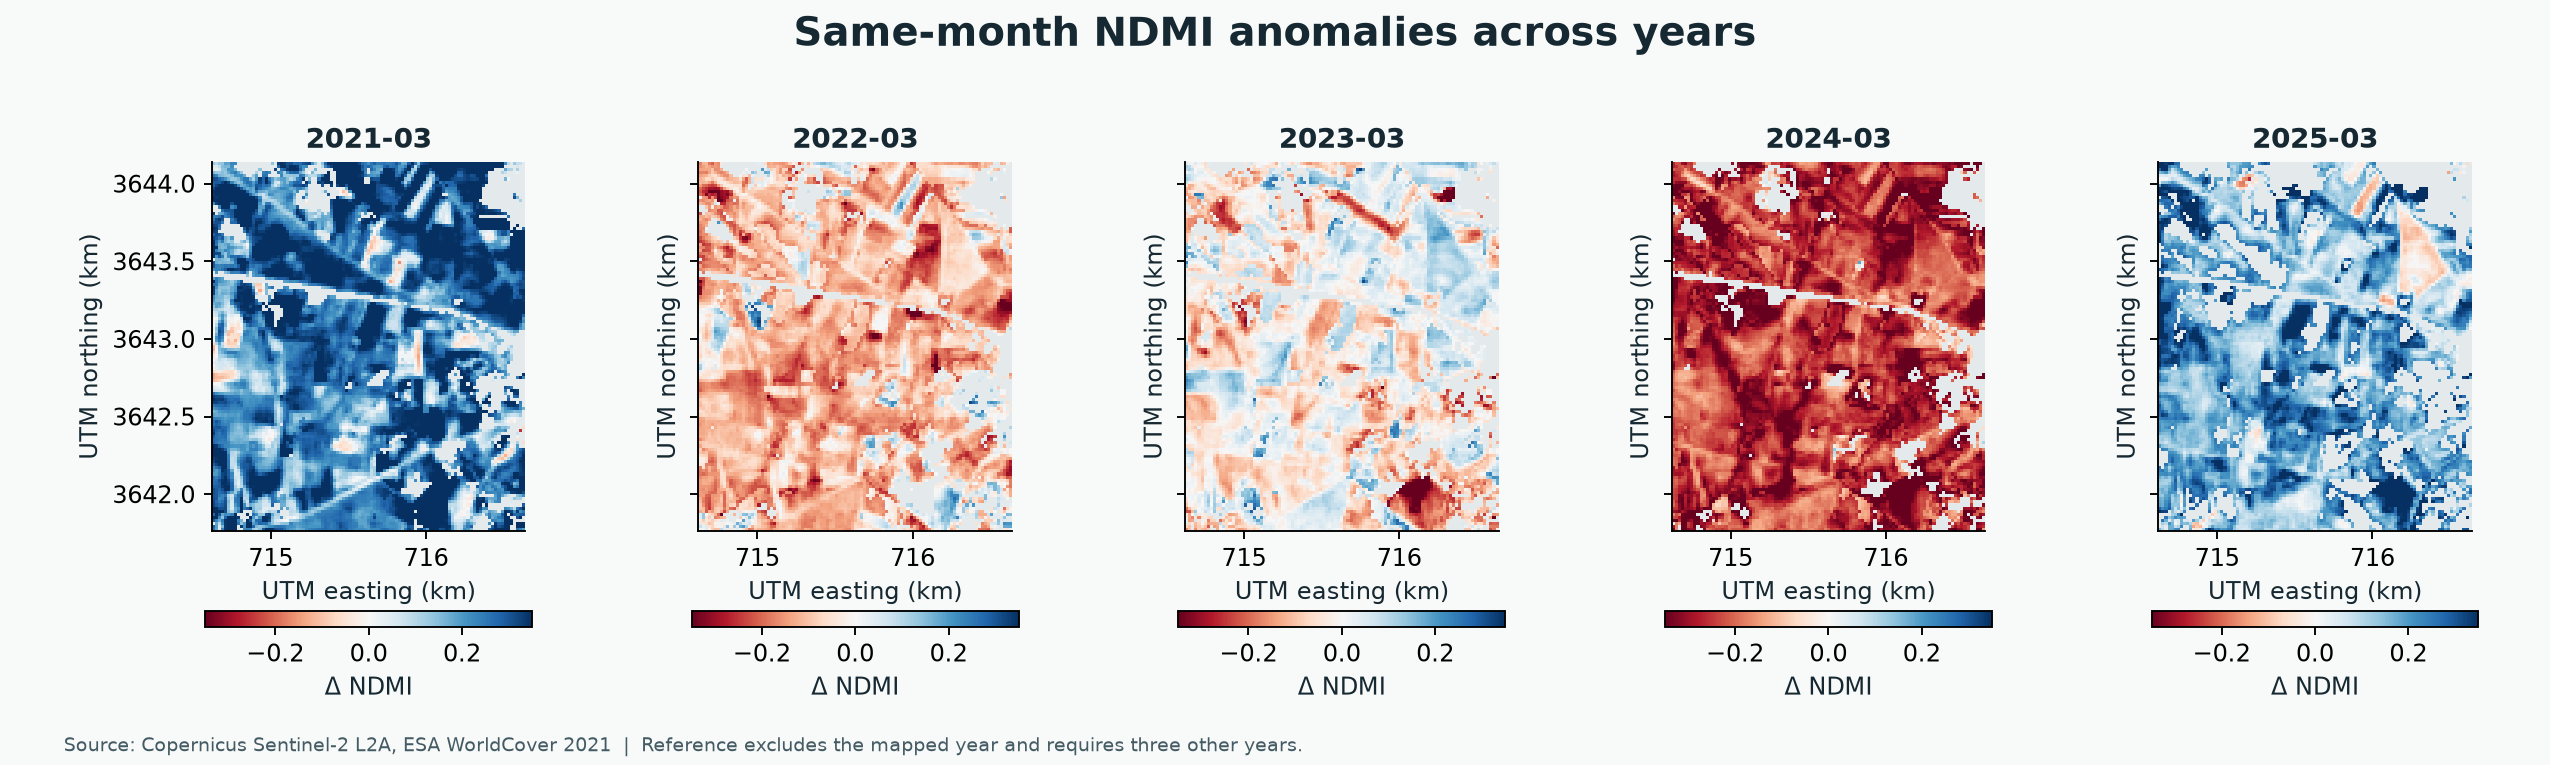

{'month': '2024-03',
 'ndmi_anomaly': -0.256384015083313,
 'antecedent_rain_mm': 41.23}

In [3]:
display(Image(filename=reports / 'figures' / 'ndmi-anomaly-maps.png', width=1000))
metrics['lowest_ndmi_anomaly']

The flagged cropland anomaly is a spectral deviation. Irrigation, harvest, phenology and overpass timing remain plausible drivers. The NASA POWER series represents a regional grid cell.